# Lab 2 — What Did the Campaign Deliver?
Name: Daryna Koval | Group: KM-42

## Setup

In [14]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

## Task 1.1 — Size

In [15]:
a = commercials[commercials["brand"] == "BRAND_A"]

print("Spots:", len(commercials))
print("Pods:", commercials["pod_id"].nunique())
print("Brands:", commercials["brand"].nunique())
print("Categories:", commercials["category"].nunique())
print("BRAND_A spots:", len(a))
print(a.groupby("network_code").size().sort_values(ascending=False).rename("spots"))

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300
network_code
FNC      40
HGTV     39
FX       38
HIST     37
FOOD     33
BRAVO    33
ABC      29
CBS      22
NBC      16
FOX      13
Name: spots, dtype: int64


## Task 1.2 — Ad load

In [16]:
c = commercials.copy()
c["hour"] = c["start_ts"].dt.floor("h")
per_hour = c.groupby(["network_code", "hour"])["length_sec"].sum() / 60

load = per_hour.groupby("network_code").agg(["mean", "count"])
load.columns = ["ad min per hour", "hours with ads"]
load = load.sort_values("ad min per hour", ascending=False)
print(load.round(1))
print("Heaviest ad load:", load["ad min per hour"].idxmax())

              ad min per hour  hours with ads
network_code                                 
FNC                      15.6             743
BRAVO                    13.4             623
HGTV                     13.3             621
HIST                     13.2             622
FOOD                     13.1             620
FX                       12.9             621
CBS                      12.1             427
ABC                      11.8             349
NBC                      11.8             299
FOX                      11.8             196
Heaviest ad load: FNC


**Answer:** FNC has the heaviest ad load: 15.6 minutes of national ads per hour (the others have 11.8-13.4).
Cable networks have national ads in almost every hour of the month (620-743 of 744 hours), but the broadcast
networks only in 196-427 hours. The reason is that broadcast networks give part of the day to their local stations.
The local stations sell the ad breaks in these hours to local advertisers, so these ads are not in the national ad log.

## Task 1.3 — Price everything

In [17]:
def to_min(t):
    h, m = t.split(":")
    return int(h) * 60 + int(m) - 360

rc = rate_card.copy()
rc["program_name"] = rc["program_name"].fillna("")
prog_rows = rc[rc["program_name"] != ""]
time_rows = rc[rc["program_name"] == ""].copy()
time_rows["start_min"] = time_rows["start_time"].map(to_min)
time_rows["end_min"] = time_rows["end_time"].map(to_min)
time_rows = time_rows.explode("weekdays")
time_rows["weekdays"] = time_rows["weekdays"].astype(int)

spots = commercials.merge(programs[["telecast_id", "program_name"]], on="telecast_id", how="left")

p = spots.merge(prog_rows[["network_code", "program_name", "daypart", "cost_30s_usd"]],
                on=["network_code", "program_name"])
p["row_kind"] = "program"

rest = spots[~spots["ad_airing_id"].isin(p["ad_airing_id"])].copy()
b = rest["start_ts"] - pd.Timedelta(hours=6)
rest["weekday"] = b.dt.dayofweek
rest["minute"] = b.dt.hour * 60 + b.dt.minute
t = rest.merge(time_rows[["network_code", "weekdays", "start_min", "end_min", "daypart", "cost_30s_usd"]],
               left_on=["network_code", "weekday"], right_on=["network_code", "weekdays"])
t = t[(t["minute"] >= t["start_min"]) & (t["minute"] < t["end_min"])]
t["row_kind"] = "time"

cols = list(spots.columns) + ["daypart", "cost_30s_usd", "row_kind"]
priced = pd.concat([p[cols], t[cols]], ignore_index=True)
priced["cost"] = priced["cost_30s_usd"] * priced["length_sec"] / 30

print("Spots without a price:", len(commercials) - priced["ad_airing_id"].nunique())
print("Spots with two prices:", priced["ad_airing_id"].duplicated().sum())

value = priced.groupby("network_code")["cost"].sum()
prog_value = priced[priced["row_kind"] == "program"].groupby("network_code")["cost"].sum()
table = pd.DataFrame({
    "value (USD M)": value / 1e6,
    "share from program rows": (prog_value / value).fillna(0),
}).sort_values("value (USD M)", ascending=False)
print(table.round({"value (USD M)": 1, "share from program rows": 3}))
print("Total rate-card value (USD M):", round(value.sum() / 1e6, 1))

Spots without a price: 0
Spots with two prices: 0
              value (USD M)  share from program rows
network_code                                        
CBS                   818.8                    0.230
NBC                   724.3                    0.342
ABC                   708.8                    0.432
FOX                   696.2                    0.835
FNC                   315.8                    0.000
HGTV                   58.1                    0.000
FX                     42.5                    0.000
FOOD                   42.1                    0.000
HIST                   40.1                    0.000
BRAVO                  25.3                    0.000
Total rate-card value (USD M): 3472.1


## Task 2.1 — Delivery

In [18]:
camp = priced[priced["brand"] == "BRAND_A"].copy()
camp["broadcast_date"] = (camp["start_ts"] - pd.Timedelta(hours=6)).dt.normalize()

daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"])
pers = daily_weights[daily_weights["resp_type"].isin(["R", "L"])]
month_w = pers.groupby("respondent_id")["weight"].mean()

va = viewer_attributes.merge(attributes, on="attr_id")
age = va[va["attr_name"] == "Age in years"].set_index("respondent_id")["value"].astype(float)
sex = va[va["attr_group"] == "Sex"].set_index("respondent_id")["attr_name"]
target = month_w.index[age.reindex(month_w.index).between(18, 49)]

v = viewings[viewings["resp_type"].isin(["R", "L"])]
rows = []
for _, s in camp.iterrows():
    w = v[(v["network_code"] == s["network_code"]) & (v["start_ts"] <= s["start_ts"]) & (v["end_ts"] > s["start_ts"])]
    rows.append(pd.DataFrame({"ad_airing_id": s["ad_airing_id"], "respondent_id": w["respondent_id"], "weight": w["weight"]}))
exp = pd.concat(rows).drop_duplicates(["ad_airing_id", "respondent_id"])
exp["target"] = exp["respondent_id"].isin(target)

def delivery(e, people):
    # e: exposures of this audience, people: respondent ids of this audience
    day_total = pers[pers["respondent_id"].isin(people)].groupby("broadcast_date")["weight"].sum()
    imp = e.groupby("ad_airing_id")["weight"].sum().reindex(camp["ad_airing_id"], fill_value=0)
    rating = imp / camp.set_index("ad_airing_id")["broadcast_date"].map(day_total) * 100
    grps = rating.sum()
    reach = month_w[e["respondent_id"].unique()].sum() / month_w[people].sum() * 100
    return imp, rating, grps, reach

imp_p, rating_p, grps_p, reach_p = delivery(exp, month_w.index)
imp_t, rating_t, grps_t, reach_t = delivery(exp[exp["target"]], target)

print("P2+ impressions (M):", round(imp_p.sum() / 1e6, 1))
print("P2+ GRPs:", round(grps_p, 1))
print("P2+ reach (%):", round(reach_p, 1))
print("P2+ average frequency:", round(grps_p / reach_p, 1))
print("A18-49 impressions (M):", round(imp_t.sum() / 1e6, 1))
print("A18-49 GRPs:", round(grps_t, 1))
print("A18-49 reach (%):", round(reach_t, 1))
print("A18-49 average frequency:", round(grps_t / reach_t, 1))

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


## Task 2.2 — Frequency distribution

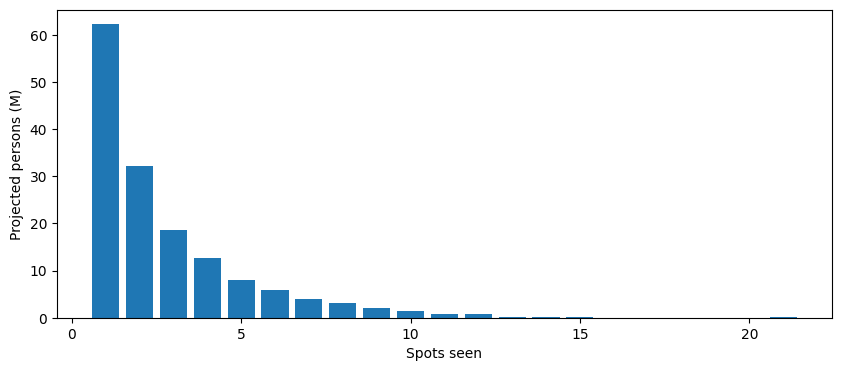

Share of impressions at 5+ exposures: 0.444
Share of reached people at 5+: 0.175


In [19]:
freq = exp.groupby("respondent_id")["ad_airing_id"].nunique()
dist = month_w[freq.index].groupby(freq).sum() / 1e6
plt.figure(figsize=(10, 4))
plt.bar(dist.index, dist.values)
plt.xlabel("Spots seen")
plt.ylabel("Projected persons (M)")
plt.show()
heavy = freq[freq >= 5].index
print("Share of impressions at 5+ exposures:", f"{exp.loc[exp['respondent_id'].isin(heavy), 'weight'].sum() / exp['weight'].sum():.3f}")
print("Share of reached people at 5+:", f"{month_w[heavy].sum() / month_w[freq.index].sum():.3f}")

**Answer:** Not really. The average frequency is 3.0, but most people saw the ad only once or twice
(62.2 M saw one spot, 32.3 M saw two). At the same time, people who saw 5 or more spots are only 17.5% of the people reached,
but they got 44.4% of all impressions. So a few heavy viewers saw the ad many times, and they pull the average up.
For most of the audience the real frequency is lower than 3.

## Task 2.3 — On target?

In [20]:
print("Share of impressions on A18-49:", f"{imp_t.sum() / imp_p.sum():.3f}")
print("A18-49 share of persons:", f"{month_w[target].sum() / month_w.sum():.3f}")
net = camp.set_index("ad_airing_id")["network_code"]
by_net = pd.DataFrame({
    "P2+ imp (M)": imp_p.groupby(net).sum() / 1e6,
    "A18-49 imp (M)": imp_t.groupby(net).sum() / 1e6,
})
by_net["A18-49 share"] = by_net["A18-49 imp (M)"] / by_net["P2+ imp (M)"]
print(by_net.sort_values("A18-49 share").round(3))

Share of impressions on A18-49: 0.194
A18-49 share of persons: 0.422
              P2+ imp (M)  A18-49 imp (M)  A18-49 share
network_code                                           
FNC                57.798           2.717         0.047
CBS                88.980          13.693         0.154
ABC                94.211          16.989         0.180
NBC                41.435           7.834         0.189
HIST               12.329           2.485         0.202
FOX                76.256          18.440         0.242
HGTV               24.657           7.554         0.306
FOOD                9.481           2.992         0.316
BRAVO               5.084           2.817         0.554
FX                  8.523           5.551         0.651


**Answer:** The campaign under-delivered against its target. A18-49 are 42.2% of all persons, but they got only 19.4%
of the campaign's impressions (an index of about 46). The big networks explain it: they carry 359 M of the 419 M impressions,
and their audiences are old. Fox News is the worst (only 4.7% of its impressions are A18-49), then CBS (15.4%),
ABC (18.0%) and NBC (18.9%). Only FX (65.1%) and Bravo (55.4%) delivered mostly the target, but they got very few
impressions. The plan bought the networks with the biggest audiences, not the ones that reach adults 18-49.

## Task 3.1 — Cost

In [21]:
cost = camp["cost"].sum()
cpp = cost / grps_p
print("Campaign cost (USD):", round(cost))
print("P2+ CPM (USD):", round(cost / imp_p.sum() * 1000, 2))
print("P2+ CPP (USD):", round(cpp))
print("A18-49 CPM (USD):", round(cost / imp_t.sum() * 1000, 2))
print("A18-49 CPP (USD):", round(cost / grps_t))

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [22]:
c = camp.set_index("ad_airing_id")
tab = pd.DataFrame({
    "spots": c.groupby("network_code").size(),
    "cost (USD)": c.groupby("network_code")["cost"].sum(),
    "P2+ imp (M)": imp_p.groupby(c["network_code"]).sum() / 1e6,
    "A18-49 imp (M)": imp_t.groupby(c["network_code"]).sum() / 1e6,
})
tab["cost share"] = tab["cost (USD)"] / cost
tab["P2+ CPM"] = tab["cost (USD)"] / tab["P2+ imp (M)"] / 1000
tab["A18-49 CPM"] = tab["cost (USD)"] / tab["A18-49 imp (M)"] / 1000
tab["cost (USD)"] = tab["cost (USD)"].round().astype(int)
tab = tab.sort_values("A18-49 CPM")
print(tab.round({"cost share": 3, "P2+ imp (M)": 1, "A18-49 imp (M)": 1, "P2+ CPM": 2, "A18-49 CPM": 2}).to_string())

              spots  cost (USD)  P2+ imp (M)  A18-49 imp (M)  cost share  P2+ CPM  A18-49 CPM
network_code                                                                                 
FX               38       92200          8.5             5.6       0.012    10.82       16.61
BRAVO            33       49610          5.1             2.8       0.007     9.76       17.61
HGTV             39      230000         24.7             7.6       0.031     9.33       30.45
HIST             37       79640         12.3             2.5       0.011     6.46       32.05
FOOD             33       96620          9.5             3.0       0.013    10.19       32.29
ABC              29     1625700         94.2            17.0       0.219    17.26       95.69
NBC              16      796800         41.4             7.8       0.107    19.23      101.72
CBS              22     1488700         89.0            13.7       0.201    16.73      108.72
FOX              13     2434700         76.3            18.4

**Answer:** The money went mostly to FOX, ABC, CBS and NBC. FOX alone took about a third of the budget
because its spots are in NFL games, which are the most expensive. The five small networks got only a small part of the money.
For the target (A18-49) the cheapest networks were FX (16.61 USD per thousand) and Bravo (17.61 USD).
HGTV, History and Food came next at a bit over 30 USD. Big networks cost 95-132 USD per thousand A18-49 impressions,
and Fox News was the worst at 193.70 USD, because its audience is mostly older people.

## Task 3.3 — Guarantee

In [23]:
owed = max(0, 150 - grps_p)
print("Guarantee met:", grps_p >= 150)
print("Make-good GRPs owed:", round(owed, 1))
print("Value of make-goods (USD):", round(owed * cpp))

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012882


## Task 4 — Do networks add up?

In [24]:
big = ["CBS", "NBC", "ABC", "FOX", "FNC"]
exp["big"] = exp["ad_airing_id"].map(c["network_code"]).isin(big)
def reach(ids):
    return month_w[pd.unique(ids)].sum() / month_w.sum() * 100
r_big = reach(exp.loc[exp["big"], "respondent_id"])
r_small = reach(exp.loc[~exp["big"], "respondent_id"])
r_all = reach(exp["respondent_id"])
overlap = r_big + r_small - r_all
cost_big = c.loc[c["network_code"].isin(big), "cost"].sum()
cost_small = cost - cost_big
print("Reach, big networks (%):", round(r_big, 1))
print("Reach, small networks (%):", round(r_small, 1))
print("Reach, whole campaign (%):", round(r_all, 1))
print("Overlap (%):", round(overlap, 1))
print("Overlap if independent (%):", round(r_big * r_small / 100, 1))
print("Reach added by small networks (points):", round(r_all - r_big, 1))
print("Cost per added reach point, small (USD):", round(cost_small / (r_all - r_big)))
print("Cost per reach point, big (USD):", round(cost_big / r_big))

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** We cannot just add the two reaches (39.8 + 12.4 = 52.2), because many people saw spots on both
groups of networks, and in the whole campaign each person is counted only once, so the total is 43.5%.
The overlap is 8.7% of all persons. If the audiences were independent it would be only 4.9%, so the real overlap
is much bigger. This means that people who watch small networks are more likely than average to also see the big ones.
I think this is because people who watch a lot of TV switch between many channels, so they meet the ad in both places.
The small networks still added 3.7 reach points, and each point cost 148,706 USD, which is less than 172,456 USD per point
on the big networks. So the money for the small networks was spent well.

## Task 5 — How sure are we?

In [25]:
pan = exp.groupby("ad_airing_id").size().reindex(c.index, fill_value=0)
n_day = pers.groupby("broadcast_date").size()
p_ = rating_p / 100
n = c["broadcast_date"].map(n_day)
se = (p_ * (1 - p_) / n) ** 0.5 * 100
rel = se / rating_p
q = pd.DataFrame({"network": c["network_code"], "panelists": pan, "rel_se": rel})
t5 = q.groupby("network").agg(median_panelists=("panelists", "median"), median_rel_se=("rel_se", "median"), zero_spots=("panelists", lambda s: (s == 0).sum()))
print(t5.round(3))
print("Spots seen by no panelist:", (pan == 0).sum())
print("Median relative SE, big networks:", round(q.loc[q["network"].isin(big), "rel_se"].median(), 3))
print("Median relative SE, small networks:", round(q.loc[~q["network"].isin(big), "rel_se"].median(), 3))
w1834 = month_w.index[age.reindex(month_w.index).between(18, 34) & (sex.reindex(month_w.index) == "Female")]
seen_w = exp[exp["respondent_id"].isin(w1834)].groupby("ad_airing_id").size().reindex(c.index, fill_value=0)
print("W18-34 zero-cell spots:", (seen_w == 0).sum())

         median_panelists  median_rel_se  zero_spots
network                                             
ABC                  57.0          0.123           0
BRAVO                 3.0          0.540           3
CBS                  69.0          0.113           0
FNC                  31.0          0.164           0
FOOD                  5.0          0.423           2
FOX                 145.0          0.080           0
FX                    5.5          0.423           4
HGTV                 11.0          0.301           0
HIST                  5.0          0.460           1
NBC                  68.5          0.115           0
Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** 10 spots, all on small networks, were seen by no panelist, so their rating is 0. This does not
mean that nobody in the US saw the ad. It means that the audience was too small for the panel to measure.
On small networks a typical spot is based on only 3-11 panelists, and the median relative error is about 42%,
compared with about 12% on big networks (spots with rating 0 are not in the median, because the relative error
is not defined for them). For women 18-34 it is even worse: 171 of 300 spots were not seen by any woman 18-34 in the panel.
So I would tell the client that we cannot give a reliable W18-34 rating for each spot. We can give it for the whole
campaign or by network, or use a bigger group like A18-49, and we should show the error together with the number.

## Bonus

In [26]:
spot = pd.DataFrame({"network": c["network_code"], "cost": c["cost"], "t_imp": imp_t})
moved = spot[spot["network"] == "FNC"].sort_values("cost", ascending=False).head(20)
fx_cpm = tab.loc["FX", "A18-49 CPM"]
new_imp = moved["cost"].sum() / fx_cpm * 1000
new_t = imp_t.sum() - moved["t_imp"].sum() + new_imp
print("Budget of the 20 FNC spots (USD):", round(moved["cost"].sum()))
print("Their A18-49 impressions (M):", round(moved["t_imp"].sum() / 1e6, 2))
print("Same money on FX (A18-49 impressions, M):", round(new_imp / 1e6, 2))
print("A18-49 CPM before / after (USD):", round(cost / imp_t.sum() * 1000, 2), round(cost / new_t * 1000, 2))
print("FX spots for this money:", round(moved["cost"].sum() / c.loc[c["network_code"] == "FX", "cost"].mean()))

Budget of the 20 FNC spots (USD): 384000
Their A18-49 impressions (M): 1.71
Same money on FX (A18-49 impressions, M): 23.12
A18-49 CPM before / after (USD): 91.53 72.41
FX spots for this money: 158


**Answer:** I would move the 20 most expensive Fox News spots (384,000 USD) to FX. On Fox News these spots
gave only 1.71 M A18-49 impressions, because only 4.7% of its audience is 18-49. On FX, with A18-49 CPM of 16.61 USD,
the same money would give about 23.1 M A18-49 impressions. Then the campaign's A18-49 CPM would go down from 91.53 to
about 72.41 USD. This is only an estimate, because FX ratings are small and based on few panelists (Task 5).